In [2]:
import os
from dotenv import load_dotenv
import json
import random
import matplotlib.pyplot as plt
import numpy as np
import asyncio
import pandas as pd

from sqlalchemy import select, func
from sqlalchemy.orm import joinedload

from benchmarklib import BenchmarkDatabase
from sat import ThreeSatTrial, ThreeSat, ThreeSatOracleTrial
from benchmarklib.compilers import CompileType, XAGCompiler, QCFCompiler

from qiskit_ibm_runtime import QiskitRuntimeService

In [3]:
grover_iter_db = BenchmarkDatabase("three_sat.db", ThreeSat, ThreeSatTrial)
oracle_db = BenchmarkDatabase("three_sat.db", ThreeSat, ThreeSatOracleTrial)

In [4]:
service = QiskitRuntimeService()
await grover_iter_db.update_all_pending_results(service=service, batch_size=2)
await oracle_db.update_all_pending_results(service=service, batch_size=2)

In [6]:
job_ids = [
    "d79vrtpq1efs73d3b9h0",
    "d79vp9qk86tc73a0rtc0",
    "d79vudjc6das739jfd10",
    "d7a0103c6das739jffog",
    "d7a03gqk86tc73a0s8r0",
]
cancelled = oracle_db.query(
    select(ThreeSatOracleTrial)
    .where(ThreeSatOracleTrial.job_id.in_(job_ids))
)

In [8]:
for trial in cancelled:
    oracle_db.delete_trial(trial.id)

In [4]:
oracle_db.query(
    select(func.count(ThreeSat.id))
)

[2000]

In [6]:
oracle_db.query(
    select(func.count(ThreeSatOracleTrial.id))
)

[14400]

In [8]:
def get_fidelity_data(oracle_db, compiler_name=None, n_iter=None):
    n_data = []
    num_solutions_data = []
    fidelity_data = []

    _aggregate_data = {}
    n_iter = list(n_iter) if n_iter is not None else list(range(1, 6))
    
    # split into batches based on n to avoid loading all trials into memory at once
    for n in n_iter:
        problems = oracle_db.query(
            select(ThreeSat)
            .where(ThreeSat.num_vars == n)
        )
        for problem in problems:
            trials = oracle_db.query(
                select(ThreeSatOracleTrial)
                .join(ThreeSatOracleTrial.problem)
                .where(ThreeSatOracleTrial.compiler_name == compiler_name)
                .where(ThreeSatOracleTrial.problem_id == problem.id)
                .options(joinedload(ThreeSatOracleTrial.problem))
            )
            
            if len(trials) == 0:
                continue

            problem_fidelities = []
            n = problem.number_of_input_bits()
            num_solutions = problem.get_num_solutions()
            for trial in trials:
                if trial.is_failed:
                    problem_fidelities.append(0.0)
                    continue
                problem_fidelities.append(trial.calculate_success_rate())

            problem_fidelity = np.mean(problem_fidelities)
            # form bins based on the number of solutions compared with total search space size 2^n
            # scale with n: thresholds are 2^(n-5), 2^(n-4), ..., 2^(n-1)
            if num_solutions == 0:
                bin_index = 0
            elif num_solutions <= 2 ** (n - 5):
                bin_index = 1
            elif num_solutions <= 2 ** (n - 4):
                bin_index = 2
            elif num_solutions <= 2 ** (n - 3):
                bin_index = 3
            elif num_solutions <= 2 ** (n - 2):
                bin_index = 4
            else:
                bin_index = 5
           
            _aggregate_data[(n, bin_index)] = _aggregate_data.get((n, bin_index), []) + [problem_fidelity]

    for n in n_iter:
        for i in range(6):
            if (n, i) not in _aggregate_data:
                _aggregate_data[(n, i)] = []

            n_data.append(n)
            num_solutions_data.append(i)
            fidelity_data.append(np.mean(_aggregate_data[(n, i)]))
    
    return n_data, num_solutions_data, fidelity_data

def _get_yticks(num_solutions_data):
    low = min(num_solutions_data)
    high = max(num_solutions_data)
    indices = []
    labels = []
    # thresholds corresponding to bin upper bounds: 0, 2^(n-5), 2^(n-4), 2^(n-3), 2^(n-2), 2^(n-1)
    bin_labels = ['0', '2^(n-5)', '2^(n-4)', '2^(n-3)', '2^(n-2)', '2^(n-1)']
    for i in range(low, high):
        indices.append(i + 0.5)
        labels.append(bin_labels[i])
    return np.array(indices), labels

def plot_fidelity_data(n_data, num_solutions_data, fidelity_data, title, filepath=None):

    df = pd.DataFrame({
        'num_vars': n_data,
        'num_solutions': num_solutions_data,
        'fidelity': fidelity_data
    })
    grid = df.pivot(index='num_solutions', columns='num_vars', values='fidelity')
    grid = grid.sort_index(ascending=True)

    plt.figure(figsize=(12, 10))
    # set NaN values to white since we do not have a full rectangle of data
    cmap = plt.cm.get_cmap("RdYlGn").copy()
    cmap.set_bad(color="white")

    plt.figure(figsize=(10, 8))
    plt.pcolormesh(
        grid.columns,
        grid.index,
        grid.values,
        cmap=cmap,
        shading='nearest',
        vmin=0,
        vmax=0.2
    )

    plt.xticks(np.arange(min(n_data), max(n_data) + 1, 1))
    plt.yticks(*_get_yticks(num_solutions_data))

    plt.xlabel('Number of Variables (n)')
    plt.ylabel('Number of Solutions (m)')
    plt.title(title)
    cbar = plt.colorbar()
    cbar.set_label(f'Mean Fidelity', rotation=270, labelpad=15)
    if filepath is not None:
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()

def plot_fidelity_data_side_by_side(n_data, num_solutions_data, fidelity_data1, fidelity_data2, title1, title2, filepath=None):
    df1 = pd.DataFrame({
        'num_vars': n_data,
        'num_solutions': num_solutions_data,
        'fidelity': fidelity_data1
    })
    grid1 = df1.pivot(index='num_solutions', columns='num_vars', values='fidelity')
    grid1 = grid1.sort_index(ascending=True)

    df2 = pd.DataFrame({
        'num_vars': n_data,
        'num_solutions': num_solutions_data,
        'fidelity': fidelity_data2
    })
    grid2 = df2.pivot(index='num_solutions', columns='num_vars', values='fidelity')
    grid2 = grid2.sort_index(ascending=True)

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))
    plot1 = axes[0].pcolormesh(
        grid1.columns, grid1.index, grid1.values,
        cmap='RdYlGn', shading='auto', vmin=0, vmax=0.2
    )
    axes[0].set_xticks(np.arange(min(n_data), max(n_data) + 1, 1))
    axes[0].set_yticks(*_get_yticks(num_solutions_data))
    axes[0].set_xlabel('Number of Variables (n)')
    axes[0].set_ylabel('Number of Solutions (m)')
    axes[0].set_title(title1)

    plot2 = axes[1].pcolormesh(
        grid2.columns, grid2.index, grid2.values,
        cmap='RdYlGn', shading='auto', vmin=0, vmax=0.2
    )
    axes[1].set_xticks(np.arange(min(n_data), max(n_data) + 1, 1))
    axes[1].set_yticks(*_get_yticks(num_solutions_data))
    axes[1].set_xlabel('Number of Variables (n)')
    axes[1].set_ylabel('Number of Solutions (m)')
    axes[1].set_title(title2)

    cbar = fig.colorbar(plot1, ax=axes.ravel().tolist(), shrink=0.95)
    cbar.set_label(f'Mean Fidelity', rotation=270, labelpad=15)
    if filepath is not None:
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()


def plot_fidelity_difference(n_data, num_solutions_data, fidelity_data1, fidelity_data2, title, filepath=None):
    difference_data = [f1 - f2 for f1, f2 in zip(fidelity_data1, fidelity_data2)]
    df = pd.DataFrame({
        'num_vars': n_data,
        'num_solutions': num_solutions_data,
        'diff': difference_data
    })
    grid = df.pivot(index='num_solutions', columns='num_vars', values='diff')
    grid = grid.sort_index(ascending=True)
    plt.figure(figsize=(12, 10))
    plt.pcolormesh(
        grid.columns, grid.index, grid.values,
        cmap='RdBu_r', shading='auto', vmin=-0.2, vmax=0.2
    )
    plt.xticks(np.arange(min(n_data), max(n_data) + 1, 1))
    plt.yticks(*_get_yticks(num_solutions_data))

    plt.xlabel('Number of Variables (n)')
    plt.ylabel('Number of Solutions (m)')
    plt.title(title)
    cbar = plt.colorbar()
    cbar.set_label(f'Difference in Fidelity', rotation=270, labelpad=15)
    if filepath is not None:
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
    plt.show()

In [6]:
n_data, num_solutions_data, fidelity_data_xag = get_fidelity_data(oracle_db, compiler_name="XAG", n_iter=range(3, 11))
n_data, num_solutions_data, fidelity_data_qcf = get_fidelity_data(oracle_db, compiler_name="CLASSICAL_FUNCTION", n_iter=range(3, 11))

/home/eriku/miniconda3/envs/tweedledum-dev/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/eriku/miniconda3/envs/tweedledum-dev/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/tmp/ipykernel_216491/2415309635.py:89: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("RdYlGn").copy()


<Figure size 1200x1000 with 0 Axes>

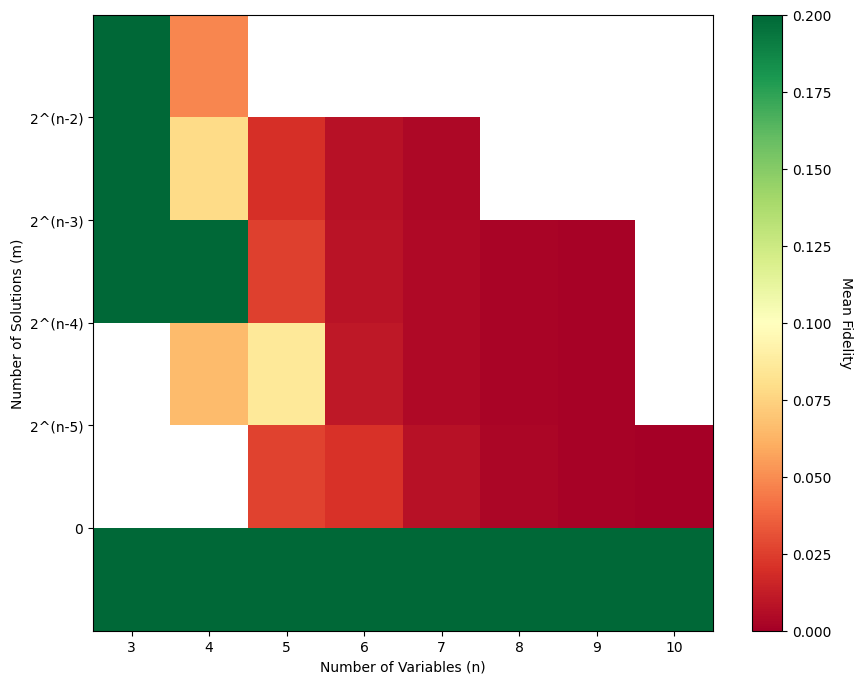

In [7]:
plot_fidelity_data(
    n_data, num_solutions_data, fidelity_data_qcf,
    title="", filepath="plots/3SAT_oracle_fidelity_QCF.png"
)

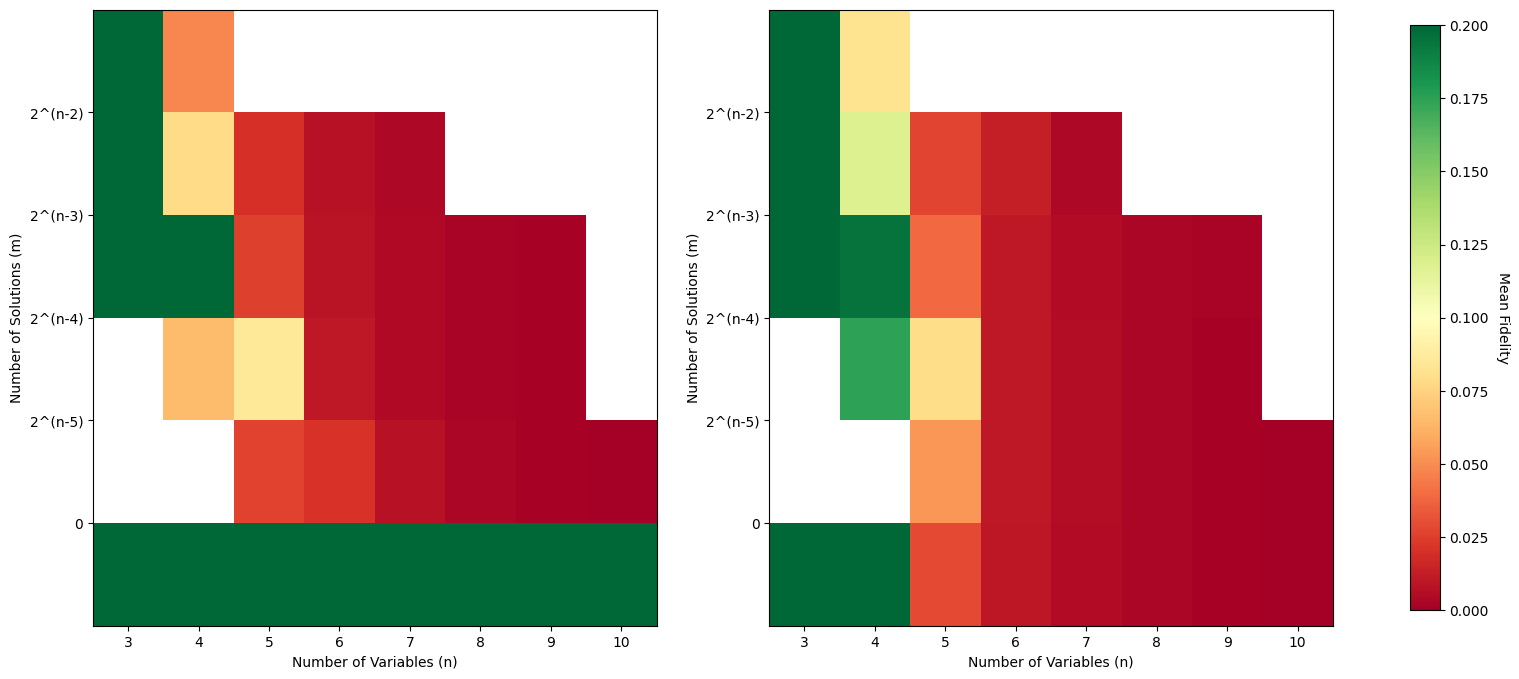

In [9]:
plot_fidelity_data_side_by_side(
    n_data, num_solutions_data, fidelity_data_qcf, fidelity_data_xag,
    title1="", title2="",
    filepath="plots/3SAT_compiler_oracle_difficulty_fidelity_comparison.png"
)

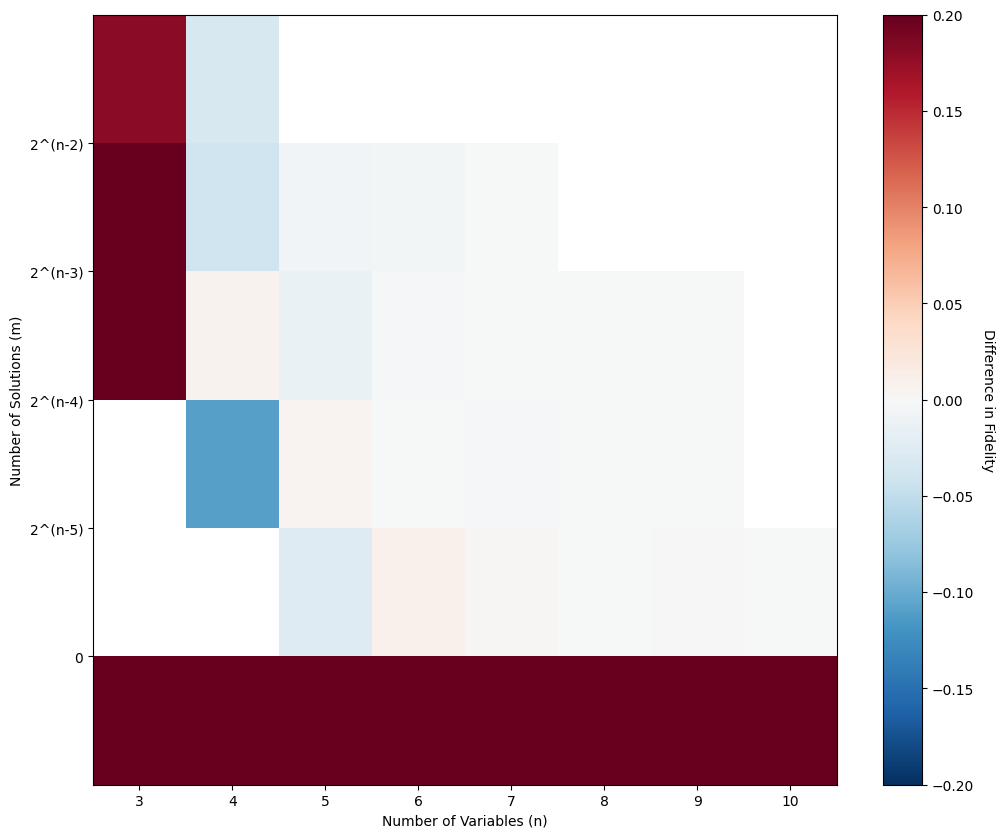

In [10]:
plot_fidelity_difference(
    n_data, num_solutions_data, fidelity_data_qcf, fidelity_data_xag,
    title="",
    filepath="plots/3SAT_compiler_oracle_difficulty_fidelity_difference.png"
)

In [5]:
trials = oracle_db.query(
    select(ThreeSatOracleTrial)
    .join(ThreeSatOracleTrial.problem)
    .where(ThreeSatOracleTrial.counts == None)
    .options(joinedload(ThreeSatOracleTrial.problem))
)

In [10]:
for t in trials:
    pass

In [6]:
len(trials)

20